 **Binary Diabetic Retinopathy — Upgraded Stacking Ensemble Pipeline**

In [ ]:
import os, shutil, random, warnings, concurrent.futures, gc, subprocess
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras.applications import InceptionResNetV2, ResNet50V2, DenseNet121
from tensorflow.keras.applications.inception_resnet_v2 import preprocess_input as inc_pre
from tensorflow.keras.applications.resnet_v2            import preprocess_input as res_pre
from tensorflow.keras.applications.densenet             import preprocess_input as den_pre
from tensorflow.keras.layers import (
    GlobalAveragePooling2D, Dense, BatchNormalization,
    Dropout, Input
)
from tensorflow.keras.models    import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import tensorflow.keras.backend as K

from sklearn.model_selection     import StratifiedKFold, train_test_split
from sklearn.utils.class_weight  import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, cohen_kappa_score, confusion_matrix,
    classification_report, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

!pip install -q imbalanced-learn lightgbm xgboost psutil
import lightgbm as lgb
import xgboost as xgb
import psutil

# ── Memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

# ── Global constants
SEED         = 42
IMG_SIZE     = 299   # ← 299 for InceptionResNetV2 native resolution
BATCH_SIZE   = 8     # ← reduced from 16 to accommodate 299×299 in 15GB GPU RAM
OOF_BATCH    = 4     # ← even smaller during OOF fine-tuning
N_CLASSES    = 5
N_FOLDS      = 5
CLASS_LABELS = ['No DR','Mild','Moderate','Severe','Proliferative DR']

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

def free_memory(label=''):
    K.clear_session()
    gc.collect()
    ram = psutil.virtual_memory()
    print(f'  [{label}] RAM: {ram.used/1e9:.1f} GB / {ram.total/1e9:.1f} GB ({ram.percent:.1f}%)')

print("TF version :", tf.__version__)
print("GPUs        :", len(tf.config.list_physical_devices('GPU')))
print(f"IMG_SIZE    : {IMG_SIZE}×{IMG_SIZE}")
print(f"BATCH_SIZE  : {BATCH_SIZE} (GPU RAM ~15 GB)")

TF version : 2.20.0
GPUs        : 1
IMG_SIZE    : 299×299
BATCH_SIZE  : 8 (GPU RAM ~15 GB)


In [ ]:
!pip install -q kaggle
from google.colab import files, drive
files.upload()   # upload kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!rm -rf /content/drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/DR_Stacking_v2/'
os.makedirs(SAVE_DIR, exist_ok=True)
print('Drive ready:', SAVE_DIR)

Saving kaggle.json to kaggle.json
Mounted at /content/drive
Drive ready: /content/drive/MyDrive/DR_Stacking_v2/


In [ ]:
!kaggle datasets download -d mariaherrerot/aptos2019 -p /content/
!unzip -q aptos2019.zip -d dataset
print('Dataset contents:', os.listdir('/content/dataset'))

Dataset URL: https://www.kaggle.com/datasets/mariaherrerot/aptos2019
License(s): unknown
100% 8.01G/8.01G [06:16<00:00, 22.8MB/s]

Dataset contents: ['test.csv', 'train_1.csv', 'test_images', 'valid.csv', 'val_images', 'train_images']


In [ ]:
train = pd.read_csv('/content/dataset/train_1.csv')
val   = pd.read_csv('/content/dataset/valid.csv')
test  = pd.read_csv('/content/dataset/test.csv')
full_df = pd.concat([train, val, test], ignore_index=True).drop_duplicates(subset='id_code')
full_df.to_csv('/content/dataset/full_aptos.csv', index=False)
print(f'Total: {len(full_df)}')
display(full_df.head())

Total: 3662


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


In [ ]:
merged = '/content/dataset/all_images'
os.makedirs(merged, exist_ok=True)
for folder in ['/content/dataset/train_images','/content/dataset/val_images',
               '/content/dataset/test_images']:
    inner = os.path.join(folder, os.path.basename(folder))
    if not os.path.exists(inner): continue
    for f in os.listdir(inner):
        dst = os.path.join(merged, f)
        if not os.path.exists(dst):
            shutil.copy(os.path.join(inner, f), dst)
print('Total images merged:', len(os.listdir(merged)))

Total images merged: 3662


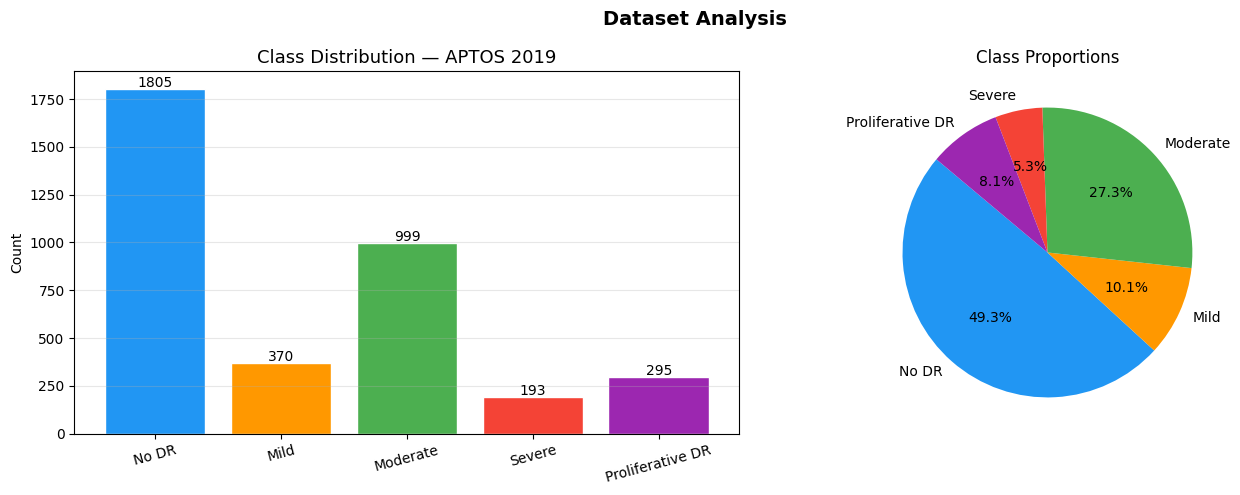

Class imbalance ratio (max/min): 9.4


In [ ]:
counts = full_df['diagnosis'].value_counts().sort_index()
colors = ['#2196F3','#FF9800','#4CAF50','#F44336','#9C27B0']

fig, axes = plt.subplots(1, 2, figsize=(14,5))
bars = axes[0].bar(CLASS_LABELS, counts.values, color=colors, edgecolor='white')
for b in bars:
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+10,
                 str(int(b.get_height())), ha='center', fontsize=10)
axes[0].set_title('Class Distribution — APTOS 2019', fontsize=13)
axes[0].set_xticklabels(CLASS_LABELS, rotation=15)
axes[0].set_ylabel('Count'); axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(counts.values, labels=CLASS_LABELS, colors=colors,
            autopct='%1.1f%%', startangle=140)
axes[1].set_title('Class Proportions')
plt.suptitle('Dataset Analysis', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()
print('Class imbalance ratio (max/min):', round(counts.max()/counts.min(), 1))

In [ ]:
# ===========================================
# Binary Label Encoding
# ===========================================

full_df["binary_label"] = (
    full_df["diagnosis"] > 0
).astype(int)

print("="*40)
print("Binary Class Distribution")
print("="*40)

print(full_df["binary_label"].value_counts())

print()

print(full_df.groupby("binary_label")["diagnosis"].value_counts())

Binary Class Distribution
binary_label
1    1857
0    1805
Name: count, dtype: int64

binary_label  diagnosis
0             0            1805
1             2             999
              1             370
              4             295
              3             193
Name: count, dtype: int64


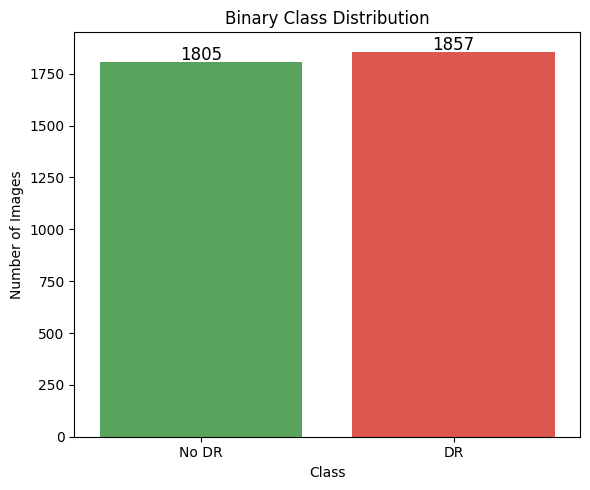

In [ ]:
#visualizing
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.countplot(
    x='binary_label',
    data=full_df,
    palette=['#4CAF50', '#F44336']
)

plt.xticks([0,1], ['No DR', 'DR'])
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Binary Class Distribution")

for i, count in enumerate(full_df['binary_label'].value_counts().sort_index()):
    plt.text(i, count+10, str(count), ha='center', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Preprocessing
RAW_DIR = '/content/raw_images_299/'
os.makedirs(RAW_DIR, exist_ok=True)


# =====================================================
# Remove Black Border
# =====================================================
def crop_black_border(img, tol=10):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = gray > tol

    if mask.any():
        img = img[np.ix_(mask.any(1), mask.any(0))]

    return img


# =====================================================
# Ben Graham Preprocessing
# =====================================================
def ben_graham(img, sigma=30):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    img = cv2.addWeighted(img, 4, blur, -4, 128)
    return img


# =====================================================
# Circular Mask
# =====================================================
def circular_mask(img):
    h, w = img.shape[:2]

    cx = w // 2
    cy = h // 2

    radius = min(cx, cy)

    mask = np.zeros((h, w), dtype=np.uint8)

    cv2.circle(mask, (cx, cy), radius, 255, -1)

    return cv2.bitwise_and(img, img, mask=mask)


# =====================================================
# CLAHE Enhancement
# =====================================================
def apply_clahe(img):

    b, g, r = cv2.split(img)

    clahe = cv2.createCLAHE(
        clipLimit=3.0,
        tileGridSize=(8,8)
    )

    b = clahe.apply(b)
    g = clahe.apply(g)
    r = clahe.apply(r)

    return cv2.merge((b,g,r))


# =====================================================
# Complete Fundus Preprocessing
# =====================================================
def preprocess_fundus(img_path, size=299):

    img = cv2.imread(img_path)

    if img is None:
        return None

    # Remove black border
    img = crop_black_border(img)

    # Ben Graham normalization
    img = ben_graham(img)

    # Keep only retina region
    img = circular_mask(img)

    # Resize
    img = cv2.resize(img, (size, size),
                     interpolation=cv2.INTER_AREA)

    # Contrast enhancement
    img = apply_clahe(img)

    return img


# =====================================================
# Process Single Image
# =====================================================
def process_row(row):

    src = f'/content/dataset/all_images/{row["id_code"]}.png'
    dst = f'{RAW_DIR}{row["id_code"]}.png'

    if not os.path.exists(src):
        return

    img = preprocess_fundus(src)

    if img is not None:
        cv2.imwrite(dst, img)


# =====================================================
# Process Entire Dataset
# =====================================================
print("="*60)
print("Preprocessing Fundus Images")
print("="*60)

with concurrent.futures.ThreadPoolExecutor(max_workers=8) as executor:

    list(
        tqdm(
            executor.map(
                process_row,
                [row for _, row in full_df.iterrows()]
            ),
            total=len(full_df),
            desc="Processing"
        )
    )

print("\nDone!")

print(f"Images Saved : {len(os.listdir(RAW_DIR))}")
print(f"Output Folder: {RAW_DIR}")

Preprocessing Fundus Images


Processing: 100%|██████████| 3662/3662 [14:32<00:00,  4.20it/s]


Done!
Images Saved : 3662
Output Folder: /content/raw_images_299/


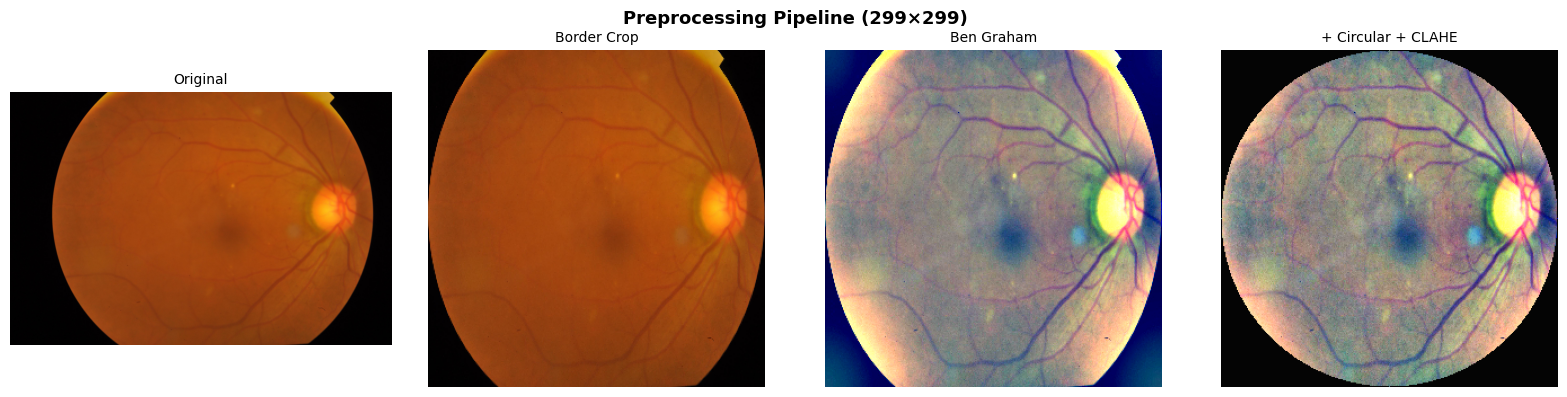

In [ ]:
sample_path = f'/content/dataset/all_images/{full_df["id_code"].iloc[0]}.png'
img_orig  = cv2.imread(sample_path)
img_crop  = crop_black_border(img_orig)
img_ben   = ben_graham(cv2.resize(img_crop,(299,299)))
img_circ  = circular_mask(img_ben)
img_clahe = apply_clahe(img_circ)

stages = [img_orig, cv2.resize(img_crop,(299,299)), img_ben, img_clahe]
titles = ['Original','Border Crop','Ben Graham','+ Circular + CLAHE']

fig, axes = plt.subplots(1,4,figsize=(16,4))
for ax,s,t in zip(axes,stages,titles):
    ax.imshow(cv2.cvtColor(s, cv2.COLOR_BGR2RGB))
    ax.set_title(t, fontsize=10); ax.axis('off')
plt.suptitle('Preprocessing Pipeline (299×299)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## Section 6 — 80/10/10 Stratified Split + Class Weights
Proper three-way split: 80% train, 10% validation (used during training), 10% test (held-out, never seen).

In [ ]:
df = full_df.copy()
df['label'] = df['binary_label']
df['filename'] = df['id_code'].astype(str) + '.png'

# ===========================
# 80 / 20 Stratified Split
# ===========================
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['label'],
    random_state=SEED
)

# Create validation set ONLY for CNN training
test_df, val_df = train_test_split(
    test_df,
    test_size=0.50,
    stratify=test_df['label'],
    random_state=SEED
)

for d in [train_df, val_df, test_df]:
    d['binary_label'] = d['binary_label'].astype(str)
    d.reset_index(drop=True, inplace=True)

print("="*60)
print("Dataset Split")
print("="*60)
print(f"Train : {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Val   : {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test  : {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

print("\nTrain Class Distribution")
print(train_df['label'].value_counts().sort_index())

train_df.to_csv(f"{SAVE_DIR}train_df.csv", index=False)
val_df.to_csv(f"{SAVE_DIR}val_df.csv", index=False)
test_df.to_csv(f"{SAVE_DIR}test_df.csv", index=False)

print(f"\nDataFrames saved to {SAVE_DIR}")

Dataset Split
Train : 2929 (80.0%)
Val   : 367 (10.0%)
Test  : 366 (10.0%)

Train Class Distribution
label
0    1444
1    1485
Name: count, dtype: int64

DataFrames saved to /content/drive/MyDrive/DR_Stacking_v2/


In [ ]:
def make_dataset(df, directory, preprocess_fn,
                  batch_size=8, shuffle=False, augment=False):
    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])   # 299×299
        img = preprocess_fn(img)
        return img, label

    def augment_fn(img, label):
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_flip_up_down(img)
        img = tf.image.random_brightness(img, 0.15)
        img = tf.image.random_contrast(img, 0.85, 1.15)
        img = tf.image.random_saturation(img, 0.8, 1.2)   # ← new
        return img, label

    paths  = [os.path.join(directory, f) for f in df['filename'].values]
    labels = df['label'].values.astype(np.float32)
    valid_mask = [os.path.exists(p) for p in paths]
    paths  = [p for p,v in zip(paths,  valid_mask) if v]
    labels = [l for l,v in zip(labels, valid_mask) if v]

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle: ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()
    if augment: ds = ds.map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds, np.array(labels)

# Build datasets
train_ds_inc, train_labels = make_dataset(train_df, RAW_DIR, inc_pre, BATCH_SIZE, True, True)
train_ds_res, _            = make_dataset(train_df, RAW_DIR, res_pre, BATCH_SIZE, True, True)
train_ds_den, _            = make_dataset(train_df, RAW_DIR, den_pre, BATCH_SIZE, True, True)

val_ds_inc,   val_labels   = make_dataset(val_df, RAW_DIR, inc_pre, BATCH_SIZE, False, False)
val_ds_res,   _            = make_dataset(val_df, RAW_DIR, res_pre, BATCH_SIZE, False, False)
val_ds_den,   _            = make_dataset(val_df, RAW_DIR, den_pre, BATCH_SIZE, False, False)

print('Train batches:', len(train_ds_inc), '| Val batches:', len(val_ds_inc))
free_memory('After dataset creation')

Train batches: 367 | Val batches: 46
  [After dataset creation] RAM: 3.0 GB / 54.8 GB (6.7%)


**Build Three Base Models**

In [ ]:
from tensorflow.keras.layers import (Input,
    GlobalAveragePooling2D,GlobalMaxPooling2D,Concatenate, BatchNormalization,Dropout, Dense
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2


def build_base_model(backbone_cls,preprocess_fn,input_shape=(IMG_SIZE, IMG_SIZE, 3),
                     dropout_rate=0.4):

    # Backbone
    base = backbone_cls(weights='imagenet',include_top=False,input_shape=input_shape )
    base.trainable = False
    inp = Input(shape=input_shape)
    x = base(inp, training=False)
    # ---------------------------------
    # Rich Feature Extraction
    # ---------------------------------
    gap = GlobalAveragePooling2D(name="gap")(x)
    gmp = GlobalMaxPooling2D(name="gmp")(x)
    features = Concatenate(name="deep_features")([gap, gmp])
    x = BatchNormalization()(features)
    x = Dropout(dropout_rate)(x)
    out = Dense(1,activation="sigmoid",kernel_regularizer=l2(1e-4),name="classifier")(x)
    model = Model(inp, out)return model, base
# ==========================================================
# Build Models
# ==========================================================
inc_model, inc_base = build_base_model(InceptionResNetV2,inc_pre)
res_model, res_base = build_base_model(ResNet50V2,res_pre)
den_model, den_base = build_base_model(DenseNet121,den_pre)
# ==========================================================
# Compile Models
# ==========================================================
for model, name in [
    (inc_model, "InceptionResNetV2"),(res_model, "ResNet50V2"),(den_model, "DenseNet121")]:
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
    model.compile(optimizer=optimizer,loss="binary_crossentropy",
                  metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.SensitivityAtSpecificity(0.90,name="sensitivity"),
            tf.keras.metrics.SpecificityAtSensitivity(0.90,name="specificity" )
 ]
    )

    print(f"{name}: {model.count_params():,} parameters")

print("=" * 60)
print("All Models Built Successfully")
print("=" * 60)
# free_memory("After model build")

219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
InceptionResNetV2: 54,352,097 parameters
ResNet50V2: 23,585,281 parameters
DenseNet121: 7,047,745 parameters
All Models Built Successfully


In [ ]:
def get_callbacks(name, monitor='val_auc'):
    return [EarlyStopping(
            monitor=monitor,patience=6,mode='max',restore_best_weights=True,verbose=1),

        ReduceLROnPlateau(monitor=monitor,
            factor=0.3,patience=3,mode='max',min_lr=1e-7,verbose=1),

        ModelCheckpoint(
            f'{SAVE_DIR}{name}.keras',
            monitor=monitor,save_best_only=True,mode='max',verbose=1)
    ]

print('Training InceptionResNetV2...')
hist_inc = inc_model.fit(train_ds_inc, validation_data=val_ds_inc,
    epochs=20,callbacks=get_callbacks('inc_p1'))

print('\nTraining ResNet50V2...')
hist_res = res_model.fit(train_ds_res, validation_data=val_ds_res,
    epochs=20,callbacks=get_callbacks('res_p1'))

print('\nTraining DenseNet121...')
hist_den = den_model.fit(train_ds_den, validation_data=val_ds_den,
    epochs=20,callbacks=get_callbacks('den_p1'))

print('Phase 1 complete.')

Training InceptionResNetV2...
Epoch 1/20
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7426 - auc: 0.8136 - loss: 0.5566 - precision: 0.7306 - recall: 0.7614 - sensitivity: 0.5232 - specificity: 0.5379
Epoch 1: val_auc improved from None to 0.94641, saving model to /content/drive/MyDrive/DR_Stacking_v2/inc_p1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DR_Stacking_v2/inc_p1.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 122s 246ms/step - accuracy: 0.8160 - auc: 0.8948 - loss: 0.4312 - precision: 0.8124 - recall: 0.8283 - sensitivity: 0.6909 - specificity: 0.6994 - val_accuracy: 0.8883 - val_auc: 0.9464 - val_loss: 0.3472 - val_precision: 0.9560 - val_recall: 0.8172 - val_sensitivity: 0.8978 - val_specificity: 0.8840 - learning_rate: 1.0000e-04
Epoch 2/20
366/367 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8802 - auc: 0.9454 - loss: 0.3037 - precision: 0.8838 - recall: 0.8743 - sensitivity: 0.8604 - specificity: 0.8563
Epoch 2: val_auc improved from 0.94641 to 0.9

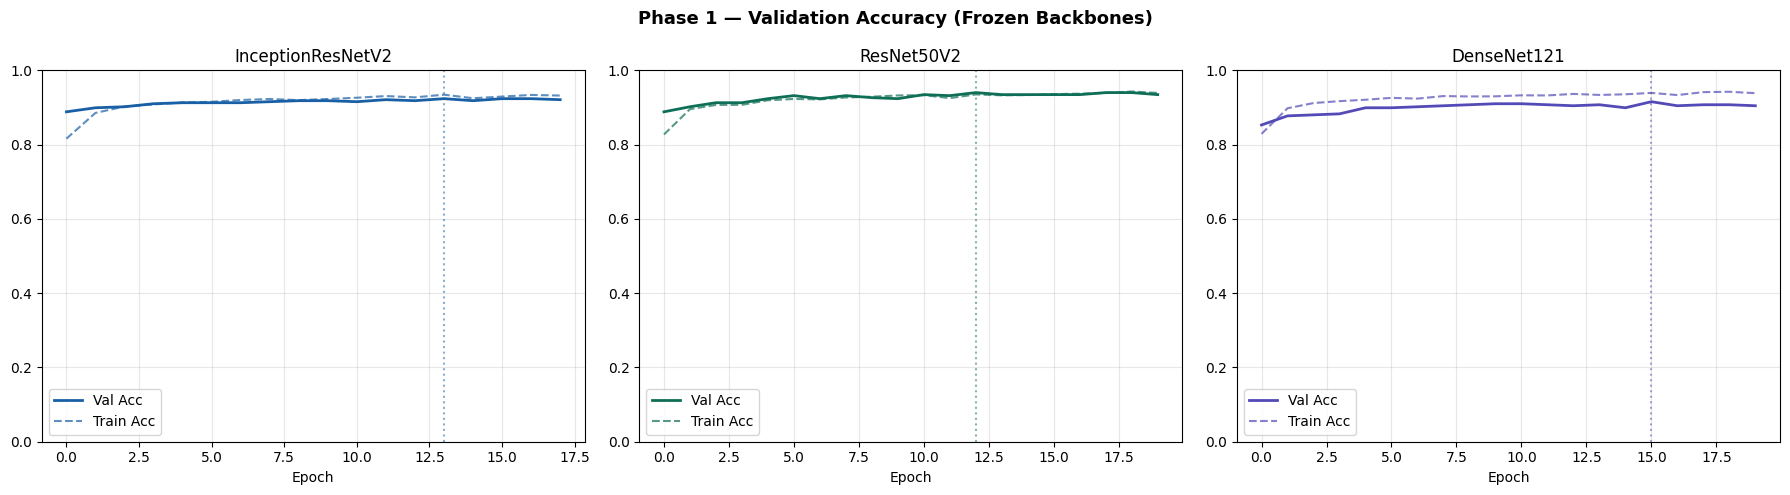

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
colors = ['#185FA5','#0F6E56','#534AB7']
names  = ['InceptionResNetV2','ResNet50V2','DenseNet121']
hists  = [hist_inc, hist_res, hist_den]

for ax, hist, color, name in zip(axes, hists, colors, names):
    ax.plot(hist.history['val_accuracy'], color=color, label='Val Acc', linewidth=2)
    ax.plot(hist.history['accuracy'], color=color, linestyle='--',
            label='Train Acc', linewidth=1.5, alpha=0.7)
    best = int(np.argmax(hist.history['val_accuracy']))
    ax.axvline(best, linestyle=':', color=color, alpha=0.5)
    ax.set_title(name, fontsize=12); ax.legend(); ax.grid(alpha=0.3)
    ax.set_xlabel('Epoch'); ax.set_ylim(0,1)

plt.suptitle('Phase 1 — Validation Accuracy (Frozen Backbones)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
from tensorflow.keras.optimizers import Adam

def fine_tune(model, base, train_ds, val_ds, save_name, unfreeze_last=80):

    print("\n" + "="*60)
    print(f"Fine-tuning {save_name}")
    print("="*60)

    # Unfreeze backbone
    base.trainable = True

    # Freeze early layers
    for layer in base.layers[:-unfreeze_last]:
        layer.trainable = False

    trainable_layers = sum(layer.trainable for layer in base.layers)
    print(f"Trainable backbone layers: {trainable_layers}/{len(base.layers)}")

    model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.SensitivityAtSpecificity(
                0.90,
                name="sensitivity"
            )
        ]
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=20,
        callbacks=get_callbacks(save_name),
        verbose=1
    )

    return history
# ==========================================================
# Fine-Tuning
# ==========================================================
hist_inc_ft = fine_tune(inc_model,inc_base,train_ds_inc,val_ds_inc,"inc_ft",
    unfreeze_last=80)
hist_res_ft = fine_tune(res_model,res_base,train_ds_res,val_ds_res,"res_ft",
    unfreeze_last=80)
hist_den_ft = fine_tune(den_model,den_base,train_ds_den,val_ds_den,"den_ft",
    unfreeze_last=80)
print("\nFine-Tuning Complete.")


Fine-tuning inc_ft
Trainable backbone layers: 80/780
Epoch 1/20
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9065 - auc: 0.9634 - loss: 0.2517 - precision: 0.9033 - recall: 0.9107 - sensitivity: 0.9160
Epoch 1: val_auc improved from None to 0.96701, saving model to /content/drive/MyDrive/DR_Stacking_v2/inc_ft.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DR_Stacking_v2/inc_ft.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 131s 246ms/step - accuracy: 0.9146 - auc: 0.9660 - loss: 0.2394 - precision: 0.9181 - recall: 0.9131 - sensitivity: 0.9205 - val_accuracy: 0.9237 - val_auc: 0.9670 - val_loss: 0.2862 - val_precision: 0.9759 - val_recall: 0.8710 - val_sensitivity: 0.9516 - learning_rate: 1.0000e-05
Epoch 2/20
366/367 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.9276 - auc: 0.9758 - loss: 0.1969 - precision: 0.9293 - recall: 0.9249 - sensitivity: 0.9384
Epoch 2: val_auc did not improve from 0.96701
367/367 ━━━━━━━━━━━━━━━━━━━━ 43s 116ms/step - accuracy: 0.9286 - a

In [ ]:
# Remove datasets to free RAM
del train_ds_inc, train_ds_res, train_ds_den
del val_ds_inc, val_ds_res, val_ds_den

gc.collect()

print("Training Complete.")
print("Models kept in memory for feature extraction.")

Training Complete.
Models kept in memory for feature extraction.


In [ ]:
# ==========================================================
# Feature Extractors
# ==========================================================

from tensorflow.keras.models import Model

inc_feature_model = Model(
    inputs=inc_model.input,
    outputs=inc_model.get_layer("deep_features").output
)

res_feature_model = Model(
    inputs=res_model.input,
    outputs=res_model.get_layer("deep_features").output
)

den_feature_model = Model(
    inputs=den_model.input,
    outputs=den_model.get_layer("deep_features").output
)

print("Feature extractors created.")

Feature extractors created.


for feature extraction use raw dataset

In [ ]:
train_ds_inc_feat, train_labels = make_dataset(train_df,
    RAW_DIR,inc_pre,BATCH_SIZE,False,False)

train_ds_res_feat, _ = make_dataset(train_df,
    RAW_DIR,res_pre,BATCH_SIZE,False,False)

train_ds_den_feat, _ = make_dataset(train_df,
    RAW_DIR,den_pre,BATCH_SIZE,False,False)

test_ds_inc_feat, test_labels = make_dataset(test_df,
    RAW_DIR,inc_pre,BATCH_SIZE,False,False)

test_ds_res_feat, _ = make_dataset(test_df,
    RAW_DIR,res_pre,BATCH_SIZE,False,False)

test_ds_den_feat, _ = make_dataset(test_df,
    RAW_DIR,den_pre,BATCH_SIZE,False,False)

In [ ]:
print("Extracting Inception Features...")
train_inc_feat = inc_feature_model.predict(
    train_ds_inc_feat,
    verbose=1
)

print("Extracting ResNet Features...")
train_res_feat = res_feature_model.predict(
    train_ds_res_feat,
    verbose=1
)

print("Extracting DenseNet Features...")
train_den_feat = den_feature_model.predict(
    train_ds_den_feat,
    verbose=1
)

Extracting Inception Features...
367/367 ━━━━━━━━━━━━━━━━━━━━ 56s 121ms/step
Extracting ResNet Features...
367/367 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step
Extracting DenseNet Features...
367/367 ━━━━━━━━━━━━━━━━━━━━ 38s 72ms/step


In [ ]:
test_inc_feat = inc_feature_model.predict(test_ds_inc_feat)
test_res_feat = res_feature_model.predict(test_ds_res_feat)
test_den_feat = den_feature_model.predict(test_ds_den_feat)

46/46 ━━━━━━━━━━━━━━━━━━━━ 13s 276ms/step
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 301ms/step


In [ ]:
print(train_inc_feat.shape)
print(train_res_feat.shape)
print(train_den_feat.shape)

(2929, 3072)
(2929, 4096)
(2929, 2048)


In [ ]:
X_train = np.concatenate(
    [train_inc_feat,train_res_feat,train_den_feat],axis=1)
X_test = np.concatenate(
    [test_inc_feat,test_res_feat,test_den_feat],axis=1)

y_train = train_labels
y_test = test_labels

print(X_train.shape)
print(X_test.shape)

(2929, 9216)
(366, 9216)


Running t-SNE... This may take a few minutes.


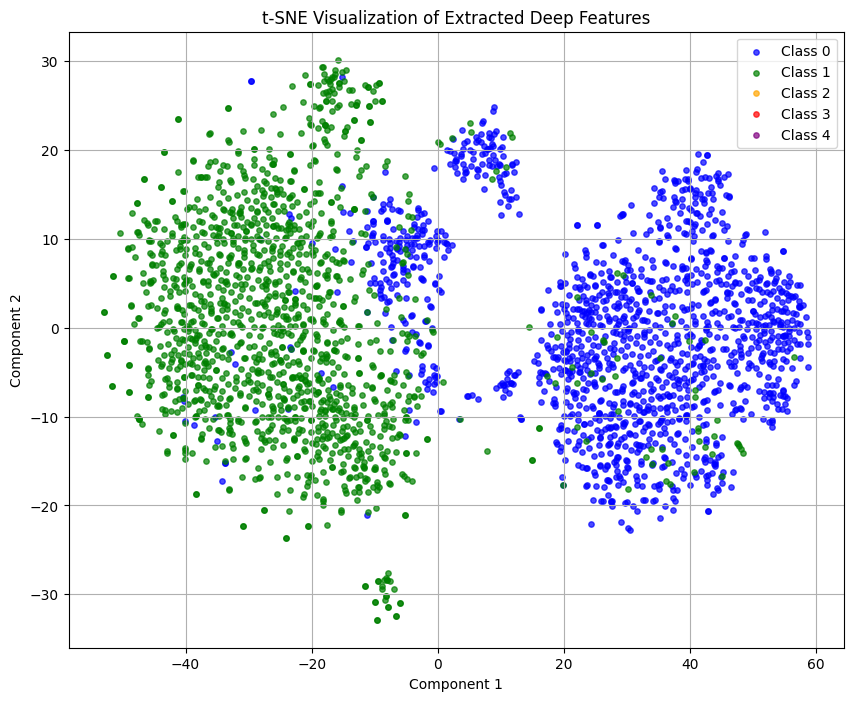

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
print("Running t-SNE... This may take a few minutes.")

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_train)
plt.figure(figsize=(10,8))

colors = ['blue','green','orange','red','purple']

for cls in range(5):
    idx = y_train == cls
    plt.scatter(
        X_tsne[idx,0],
        X_tsne[idx,1],
        s=15,
        alpha=0.7,
        color=colors[cls],
        label=f'Class {cls}'
    )

plt.title("t-SNE Visualization of Extracted Deep Features")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend()
plt.grid(True)

plt.show()

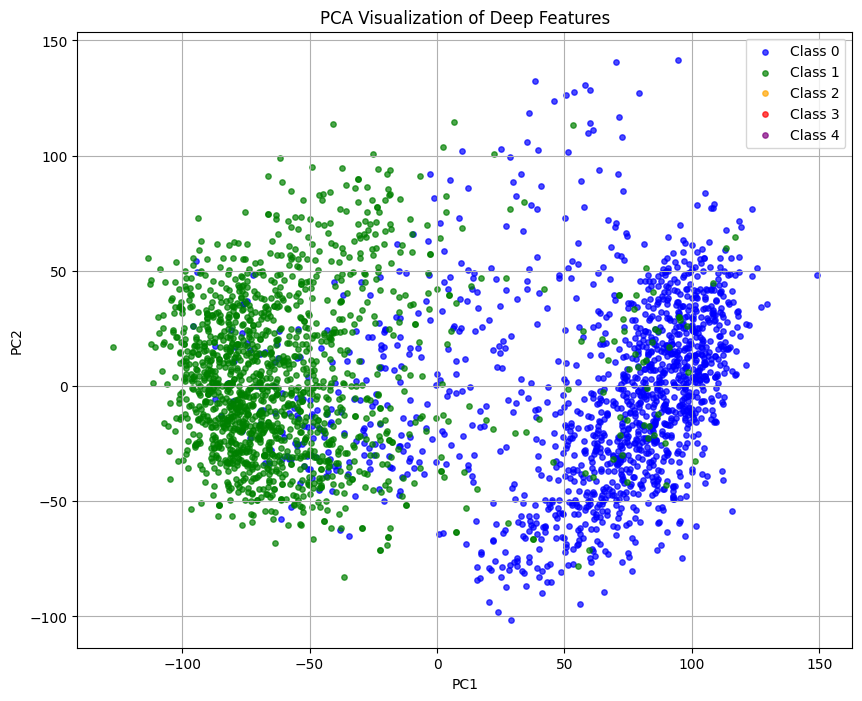

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train)

plt.figure(figsize=(10,8))

colors = ['blue','green','orange','red','purple']

for cls in range(5):
    idx = y_train == cls
    plt.scatter(
        X_pca[idx,0],
        X_pca[idx,1],
        s=15,
        alpha=0.7,
        color=colors[cls],
        label=f'Class {cls}'
    )

plt.title("PCA Visualization of Deep Features")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
import joblib

In [ ]:
# =====================================================
# Mutual Information Feature Selection
# =====================================================

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=1024
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

print("Original Train :", X_train.shape)
print("Selected Train :", X_train_selected.shape)

print("Original Test  :", X_test.shape)
print("Selected Test  :", X_test_selected.shape)

Original Train : (2343, 9216)
Selected Train : (2343, 1024)
Original Test  : (733, 9216)
Selected Test  : (733, 1024)


In [ ]:
"""joblib.dump(
    selector,
    SAVE_DIR + "mi_selector.pkl"
)

print("MI selector saved.")"""

MI selector saved.


In [ ]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
import numpy as np

# Re-initialize and fit the selector to ensure 'scores_' is available
# Using k=2000 as in the last executed SelectKBest cell (499D21zrE-N9)
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=2000
)

# X_train and y_train are expected to be available from previous cells
selector.fit_transform(X_train, y_train)

scores = selector.scores_

print("Maximum MI :", np.max(scores))
print("Average MI :", np.mean(scores))
print("Minimum MI :", np.min(scores))

Maximum MI : 0.4433636114414492
Average MI : 0.0739229921918555
Minimum MI : 0.0


In [ ]:
print("Features with MI > 0.30 :", np.sum(scores > 0.30))
print("Features with MI > 0.20 :", np.sum(scores > 0.20))
print("Features with MI > 0.10 :", np.sum(scores > 0.10))
print("Features with MI > 0.05 :", np.sum(scores > 0.05))
print("Features with MI = 0    :", np.sum(scores == 0))

Features with MI > 0.30 : 163
Features with MI > 0.20 : 701
Features with MI > 0.10 : 2362
Features with MI > 0.05 : 4499
Features with MI = 0    : 216


In [ ]:
inc_mi = scores[:3072]
res_mi = scores[3072:3072+4096]
den_mi = scores[3072+4096:]

print("Inception Mean MI :", inc_mi.mean())
print("ResNet Mean MI    :", res_mi.mean())
print("DenseNet Mean MI  :", den_mi.mean())

print()
print("Top >0.2")
print("Inception :", np.sum(inc_mi > 0.2))
print("ResNet    :", np.sum(res_mi > 0.2))
print("DenseNet  :", np.sum(den_mi > 0.2))

Inception Mean MI : 0.0598286654638612
ResNet Mean MI    : 0.07033923547357299
DenseNet Mean MI  : 0.10223199572041197

Top >0.2
Inception : 78
ResNet    : 271
DenseNet  : 352


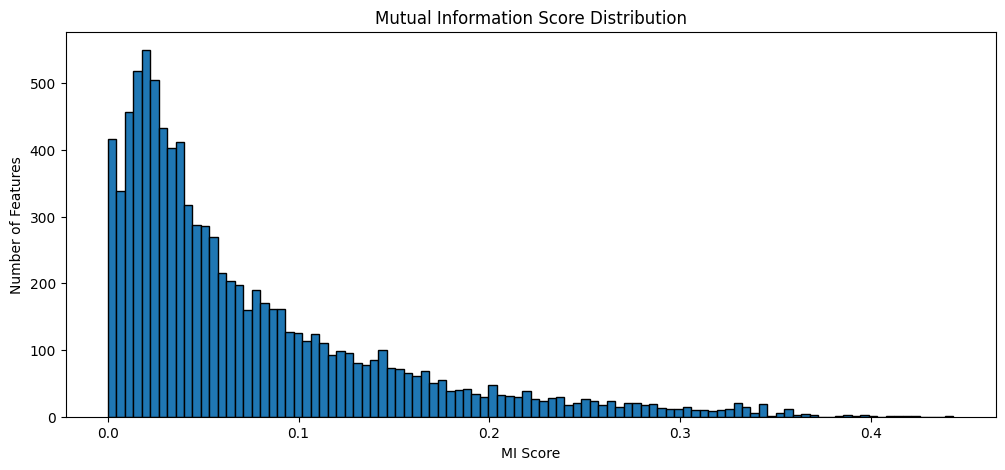

In [ ]:
plt.figure(figsize=(12,5))

plt.hist(
    scores,
    bins=100,
    edgecolor="black"
)

plt.title("Mutual Information Score Distribution")
plt.xlabel("MI Score")
plt.ylabel("Number of Features")

plt.show()

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest

print("Calculating Mutual Information...")

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=2000
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

print(X_train_selected.shape)
print(X_test_selected.shape)

Calculating Mutual Information...
(2343, 2000)
(733, 2000)


In [ ]:
selected_idx = selector.get_support(indices=True)

inc = np.sum(selected_idx < 3072)
res = np.sum((selected_idx >= 3072) & (selected_idx < 7168))
den = np.sum(selected_idx >= 7168)

print("Inception :", inc)
print("ResNet    :", res)
print("DenseNet  :", den)

Inception : 467
ResNet    : 843
DenseNet  : 690


feature sw

In [ ]:
#
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
import joblib
#feature selection
selector = SelectKBest(score_func=mutual_info_classif,k=2000)

X_train_selected = selector.fit_transform(X_train,y_train)

X_test_selected = selector.transform(X_test)

scaler = StandardScaler()

X_train_selected = scaler.fit_transform(X_train_selected)
X_test_selected = scaler.transform(X_test_selected)

joblib.dump(scaler, SAVE_DIR + "feature_scaler.pkl")

print(X_train_selected.shape)
print(X_test_selected.shape)

(2929, 2000)
(366, 2000)


In [ ]:
import lightgbm as lgb

lgb_params = {

    "objective": "multiclass",
    "num_class": 5,

    "metric": "multi_logloss",

    "learning_rate": 0.03,

    "num_leaves": 63,
    "max_depth": 8,

    "min_child_samples": 10,

    "feature_fraction": 0.85,
    "bagging_fraction": 0.85,
    "bagging_freq": 5,

    "lambda_l1": 0.5,
    "lambda_l2": 0.5,

    "verbosity": -1,

    "seed": SEED
}

train_set = lgb.Dataset(X_train_selected,label=y_train)

valid_set = lgb.Dataset(X_test_selected,label=y_test)

model = lgb.train(lgb_params,train_set,num_boost_round=1000,valid_sets=[valid_set],
        callbacks=[lgb.early_stopping(50),lgb.log_evaluation(50)])

Training until validation scores don't improve for 50 rounds
[50]	valid_0's multi_logloss: 0.160528
[100]	valid_0's multi_logloss: 0.128104
[150]	valid_0's multi_logloss: 0.135117
Early stopping, best iteration is:
[105]	valid_0's multi_logloss: 0.127055


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    f1_score
)

# Define binary class labels for the current binary classification context
CLASS_LABELS_BINARY = ['No DR', 'DR']

# Prediction
pred_prob = model.predict(
    X_test_selected,
    num_iteration=model.best_iteration
)

pred = np.argmax(pred_prob, axis=1)

print("="*60)
print("Accuracy :", accuracy_score(y_test, pred))
print("F1 Score :", f1_score(y_test, pred, average="weighted"))
print("QWK      :", cohen_kappa_score(y_test, pred, weights="quadratic"))
print("="*60)

print(classification_report(
    y_test,
    pred,
    target_names=CLASS_LABELS_BINARY  # Use binary labels here
))

cm = confusion_matrix(y_test, pred)
print(cm)

Accuracy : 0.9590163934426229
F1 Score : 0.9590179234695232
QWK      : 0.9180180987366724
              precision    recall  f1-score   support

       No DR       0.96      0.96      0.96       180
          DR       0.96      0.96      0.96       186

    accuracy                           0.96       366
   macro avg       0.96      0.96      0.96       366
weighted avg       0.96      0.96      0.96       366

[[173   7]
 [  8 178]]


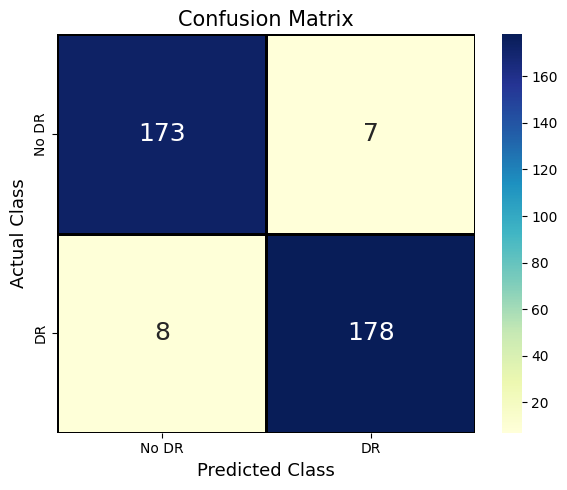

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    cbar=True,
    xticklabels=['No DR','DR'],
    yticklabels=['No DR','DR'],
    linewidths=1,
    linecolor='black',
    annot_kws={"size":18}
)

plt.xlabel("Predicted Class",fontsize=13)
plt.ylabel("Actual Class",fontsize=13)
plt.title("Confusion Matrix",fontsize=15)

plt.tight_layout()
plt.show()

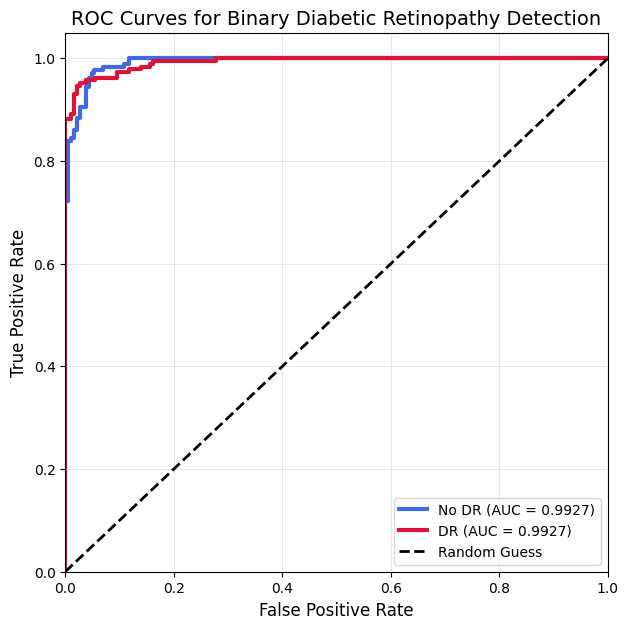

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# y_test contains binary labels (0 or 1)
# pred_prob contains probabilities for 5 classes (N, 5)

plt.figure(figsize=(7,7))

colors = ['royalblue', 'crimson']
class_names = ['No DR', 'DR']

# Iterate for the binary classes (0 and 1)
for i in range(2):
    # For true labels: check if y_test matches the current binary class 'i'
    # For predicted scores: use the corresponding column from pred_prob.
    # We assume pred_prob[:, 0] corresponds to 'No DR' (true label 0)
    # and pred_prob[:, 1] corresponds to 'DR' (true label 1).

    fpr, tpr, _ = roc_curve((y_test == i).astype(int), pred_prob[:, i])

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr,tpr,lw=3,color=colors[i],
        label=f'{class_names[i]} (AUC = {roc_auc:.4f})')

# Random classifier
plt.plot(
    [0,1],[0,1],'k--',lw=2,
    label='Random Guess'
)

plt.xlim([0,1])
plt.ylim([0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves for Binary Diabetic Retinopathy Detection", fontsize=14)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test,pred).ravel()

sensitivity = tp/(tp+fn)

specificity = tn/(tn+fp)

precision = tp/(tp+fp)

npv = tn/(tn+fn)

fpr = fp/(fp+tn)

fnr = fn/(fn+tp)

accuracy = (tp+tn)/(tp+tn+fp+fn)

print("="*40)
print(f"Sensitivity : {sensitivity:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"NPV         : {npv:.4f}")
print(f"FPR         : {fpr:.4f}")
print(f"FNR         : {fnr:.4f}")
print(f"Accuracy    : {accuracy:.4f}")

Sensitivity : 0.9570
Specificity : 0.9611
Precision   : 0.9622
NPV         : 0.9558
FPR         : 0.0389
FNR         : 0.0430
Accuracy    : 0.9590


In [ ]:
from sklearn.metrics import matthews_corrcoef

mcc = matthews_corrcoef(y_test,pred)

print("MCC :",mcc)

MCC : 0.9180318102197284


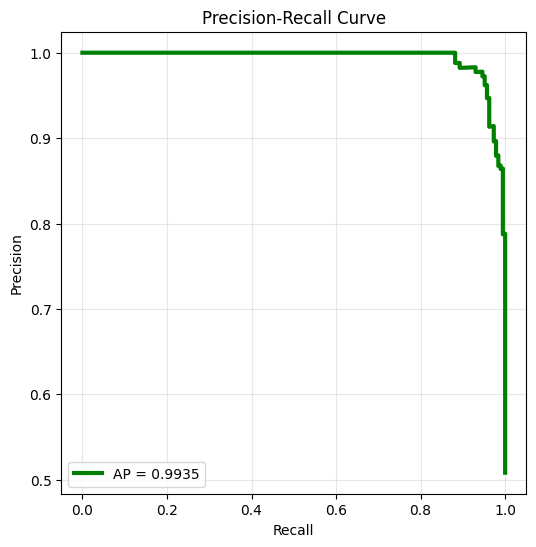

In [ ]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

precision, recall, _ = precision_recall_curve(
    y_test,
    pred_prob[:,1]
)

ap = average_precision_score(
    y_test,
    pred_prob[:,1]
)

plt.figure(figsize=(6,6))

plt.plot(
    recall,
    precision,
    lw=3,
    color='green',
    label=f"AP = {ap:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [ ]:
import joblib

joblib.dump(selector, SAVE_DIR + "mi_selector.pkl")
model.save_model(
    SAVE_DIR + "lightgbm_binary.txt"
)
import joblib

class_names = {
    0: "No DR",
    1: "DR"
}

joblib.dump(
    class_names,
    SAVE_DIR + "class_names.pkl"
)

['/content/drive/MyDrive/DR_Stacking_v2/class_names.pkl']

In [ ]:
import os

for file in os.listdir("/content/drive/MyDrive/DR_Stacking_v2"):
    print(file)

mi_selector.pkl
inc_ft.keras
res_ft.keras
den_ft.keras
feature_scaler.pkl
test_df.csv
val_df.csv
train_df.csv
inc_p1.keras
res_p1.keras
den_p1.keras
lightgbm_binary.txt
class_names.pkl


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/DR_Stacking_v2/"

required_files = [
    "inc_ft.keras",
    "res_ft.keras",
    "den_ft.keras",
    "lightgbm_binary.txt",
    "mi_selector.pkl",
    "class_names.pkl"
]

print("="*60)
print("Checking Required Files")
print("="*60)

for file in required_files:
    if os.path.exists(os.path.join(SAVE_DIR, file)):
        print(f"✅ {file}")
    else:
        print(f"❌ {file} (Missing)")

Checking Required Files
✅ inc_ft.keras
✅ res_ft.keras
✅ den_ft.keras
✅ lightgbm_binary.txt
✅ mi_selector.pkl
✅ class_names.pkl


In [ ]:
import os
import zipfile

SAVE_DIR = "/content/drive/MyDrive/DR_Stacking_v2/"
ZIP_NAME = "/content/DR_Binary_Flask_Models.zip"

files_to_zip = [
    "inc_ft.keras",
    "res_ft.keras",
    "den_ft.keras",
    "lightgbm_binary.txt",
    "mi_selector.pkl",
    "class_names.pkl",
    "feature_scaler.pkl"   # Remove this if you didn't actually use it
]

with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        filepath = os.path.join(SAVE_DIR, file)
        if os.path.exists(filepath):
            zipf.write(filepath, arcname=file)
            print(f"✅ Added: {file}")
        else:
            print(f"❌ Missing: {file}")

print("\nZIP created successfully:")
print(ZIP_NAME)

✅ Added: inc_ft.keras
✅ Added: res_ft.keras
✅ Added: den_ft.keras
✅ Added: lightgbm_binary.txt
✅ Added: mi_selector.pkl
✅ Added: class_names.pkl
✅ Added: feature_scaler.pkl

ZIP created successfully:
/content/DR_Binary_Flask_Models.zip


In [ ]:
from google.colab import files

files.download("/content/DR_Binary_Flask_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

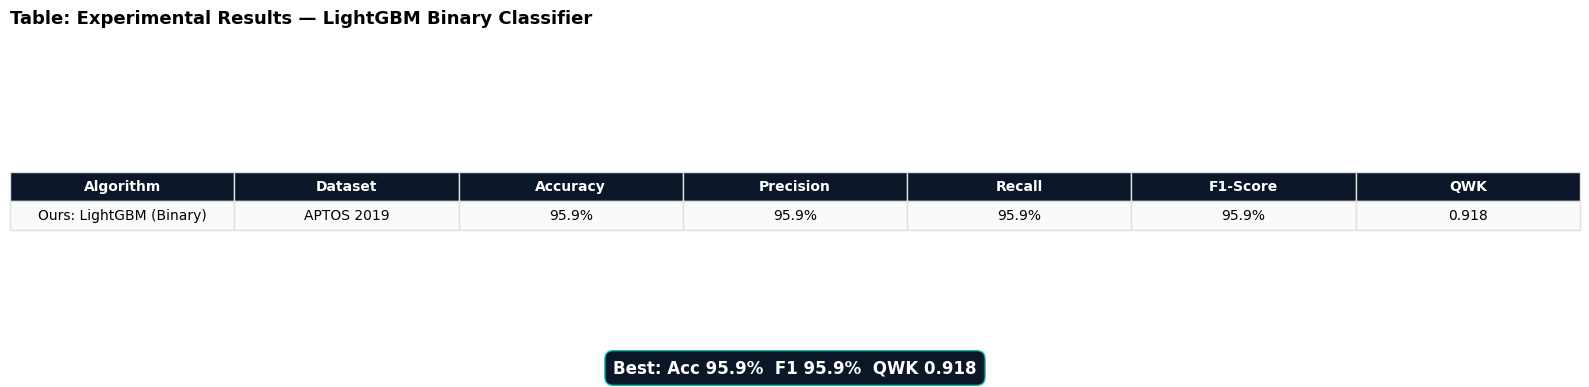

All results saved.


In [ ]:
val_acc_final = accuracy_score(y_test, pred)
val_f1_final  = f1_score(y_test, pred, average='weighted', zero_division=0)
val_pre_final = precision_score(y_test, pred, average='weighted', zero_division=0)
val_rec_final = recall_score(y_test, pred, average='weighted', zero_division=0)
val_qwk_final = cohen_kappa_score(y_test, pred, weights='quadratic')

results_data = {
    'Algorithm' : ['Ours: LightGBM (Binary)'],
    'Dataset'   : ['APTOS 2019'],
    'Accuracy'  : [f'{val_acc_final*100:.1f}%'],
    'Precision' : [f'{val_pre_final*100:.1f}%'],
    'Recall'    : [f'{val_rec_final*100:.1f}%'],
    'F1-Score'  : [f'{val_f1_final*100:.1f}%'],
    'QWK'       : [f'{val_qwk_final:.3f}']
}

results_df = pd.DataFrame(results_data)
fig, ax = plt.subplots(figsize=(16,4))
ax.axis('off')
ax.text(0.0, 1.1, 'Table: Experimental Results — LightGBM Binary Classifier',
        fontsize=13, fontweight='bold', transform=ax.transAxes)
table = ax.table(cellText=results_df.values, colLabels=results_df.columns,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1,1.8)
for (r,c), cell in table.get_celld().items():
    cell.set_edgecolor('#e0e0e0')
    if r == 0:
        cell.set_facecolor('#0b1628'); cell.set_text_props(color='white', weight='bold')
    elif r == 3:
        cell.set_facecolor('#e3f2fd'); cell.set_text_props(color='#0d47a1', weight='bold')
    else:
        cell.set_facecolor('#fafafa')
ax.text(0.5, -0.08,
        f'Best: Acc {val_acc_final*100:.1f}%  F1 {val_f1_final*100:.1f}%  QWK {val_qwk_final:.3f}',
        fontsize=12, color='white', fontweight='bold', ha='center', transform=ax.transAxes,
        bbox=dict(facecolor='#0b1628',edgecolor='#14b8a6',boxstyle='round,pad=0.5'))
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}results_table.png', dpi=300, bbox_inches='tight')
plt.show()
print('All results saved.')